In [1]:
import os
import sys
import requests
import datetime as dt
import numpy as np
from dotenv import load_dotenv
from pathlib import Path
import requests
import pandas as pd
import talib as ta
import plotly.graph_objs as go

import ipywidgets as widgets
from ipywidgets import Dropdown, Text, Button, Output
from IPython.display import display

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.reques_api import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension

In [2]:
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()

#### WTIの時系列データを取得

In [3]:
wti = 'CL=F'
start = '1999-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')
response = request_api.update_commodity_timeseries_data(
    code=wti,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [4]:
wti_df = request_api.get_commodity_time_series_data(
    code=wti,
    market=None,
    start=start,
    end=end
)
wti_df.head()

取得件数: 6564


,id,commodity_id,commodity_code,commodity_market,date,open,high,low,close,adj_close,...,rci26,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,6530,2,CL=F,None,2000-08-23,32.049999,32.799999,31.950001,31.950001,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,6531,2,CL=F,None,2000-08-24,31.629999,32.240002,31.400000,31.900000,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,6532,2,CL=F,None,2000-08-25,32.049999,32.099998,31.320000,31.700001,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,6533,2,CL=F,None,2000-08-28,32.869999,32.919998,31.860001,32.040001,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,6534,2,CL=F,None,2000-08-29,32.720001,33.029999,32.560001,32.820000,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### S&P500の時系列データを取得

In [5]:
sp500 = '^GSPC'

response = request_api.update_stock_timeseries_data(
    code=sp500,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [6]:
sp_timeseries_df = request_api.get_stock_time_series_data(
    code=sp500,
    market=None,
    start=start,
    end=end
)
sp_timeseries_df.head()

取得件数: 7018


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1064856,^GSPC,None,1998-11-17,1139.319946,1151.709961,1129.670044,1135.869995,705200000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1064857,^GSPC,None,1998-11-18,1144.479980,1144.520020,1133.069946,1139.319946,652510000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1064858,^GSPC,None,1998-11-19,1152.609985,1155.099976,1144.420044,1144.479980,671000000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1064859,^GSPC,None,1998-11-20,1163.550049,1163.550049,1152.609985,1152.609985,721200000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1064860,^GSPC,None,1998-11-23,1188.209961,1188.209961,1163.550049,1163.550049,774100000,1147.165991,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### CVXの時系列データを取得

In [7]:
cvx = 'CVX'

response = request_api.update_stock_timeseries_data(
    code=cvx,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [8]:
cvx_timeseries_df = request_api.get_stock_time_series_data(
    code=cvx,
    market=None,
    start=start,
    end=end
)
cvx_timeseries_df

取得件数: 7018


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1141472,CVX,None,1998-11-17,14.399458,14.845262,14.388313,14.811826,3258800,NaN,...,NaN,NaN,False,NaN,NaN,NaN,0.729272,NaN,NaN,False
1,1141473,CVX,None,1998-11-18,14.475368,14.643817,14.295690,14.531518,2682400,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,88.333333,NaN,False
2,1141474,CVX,None,1998-11-19,14.419216,14.587665,14.374296,14.565205,2557200,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1141475,CVX,None,1998-11-20,14.531517,14.610126,14.396758,14.475367,2896800,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1141476,CVX,None,1998-11-23,14.430445,14.531514,14.228306,14.531514,2614200,14.583086,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,91.247863,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7013,1148486,CVX,None,2026-10-07,205.149994,210.139999,204.860001,208.440002,5733000,205.794003,...,204.559413,67.830616,False,NaN,NaN,NaN,NaN,NaN,NaN,True
7014,1165754,CVX,None,2026-10-08,211.550003,212.360001,208.960007,209.320007,7620800,206.992004,...,204.524535,65.909673,False,NaN,NaN,NaN,NaN,85.000000,NaN,True
7015,1187722,CVX,None,2026-10-09,211.979996,213.720001,210.710007,211.050003,6298800,208.242004,...,204.508249,64.688807,False,NaN,NaN,NaN,NaN,NaN,NaN,False
7016,1268165,CVX,None,2026-10-12,215.000000,216.669998,213.750000,214.539993,8302800,209.784003,...,204.560629,64.441219,True,209.784003,NaN,NaN,NaN,NaN,NaN,False


In [9]:
def stock_prices_and_oil_prices(
        code: str,
        name: str,
        start: str,
        end: str,
        df_sp: pd.DataFrame | None = None,
        df_wti: pd.DataFrame | None = None,
        #df_silver: pd.DataFrame | None = None,
    ):
    # /api/v1/time_series_data/stock/
    response = request_api.get_stock_time_series_data(
        code=code,
        market=None,
        start=start,
        end=end
    )
    df_stock = pd.DataFrame(response)

    # S&P500を統合
    if df_sp is not None:
        df_sp_tmp = df_sp.copy() if df_sp is not None else pd.DataFrame()
        if "date" not in df_sp_tmp.columns:
            df_sp_tmp = df_sp_tmp.reset_index()

        df_sp_tmp["date"] = pd.to_datetime(df_sp_tmp["date"])
        df_sp_tmp = df_sp_tmp.set_index("date")
        df_sp_tmp = df_sp_tmp.loc[start:end]

    # WTI原油価格を統合
    if df_wti is not None:
        df_wti_tmp = df_wti.copy() if df_wti is not None else pd.DataFrame()
        if "date" not in df_wti_tmp.columns:
            df_wti_tmp = df_wti_tmp.reset_index()
        df_wti_tmp["date"] = pd.to_datetime(df_wti_tmp["date"])
        df_wti_tmp = df_wti_tmp.set_index("date")
        df_wti_tmp = df_wti_tmp.loc[start:end]

    # 株価時系列データを整形
    df = df_stock.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date")
    df = df.loc[start:end]


    # インデックスを揃えて結合
    if df_sp is not None:
        df["MA50_SP"] = df_sp_tmp["ma50"].reindex(df.index)
        df["MA200_SP"] = df_sp_tmp["ma200"].reindex(df.index)
    if df_wti is not None:
        df["MA50_WTI"] = df_wti_tmp["ma50"].reindex(df.index)
        df["MA200_WTI"] = df_wti_tmp["ma200"].reindex(df.index)

    show_plot = ShowPlot()
    fig = show_plot.create_basic_chart(
        df=df.reset_index(),
        code=code,
        name=name,
        start=start,
        end=end,
        ma5=False,
        ma25=False,
        ma50=True,
        ma100=False,
        ma150=False,
        ma200=True,
    )
    # ★ 2つのY軸を定義（左：HYMC、右：SP500 & GOLD）
    fig.update_layout(
        yaxis=dict(
            title=f"{name} Price",
            side="left"
        ),
        yaxis2=dict(
            title="SP500 / WTI",
            overlaying="y",
            side="right"
        )
    )

    # --- SP500（右軸） ---
    if df_sp is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_SP"],
                name="SP_MA50",
                line={"color": "blue", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_SP"],
                name="SP_MA200",
                line={"color": "gray", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    # --- WTI（右軸） ---
    if df_wti is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_WTI"],
                name="WTI_MA50",
                line={"color": "orange", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_WTI"],
                name="WTI_MA200",
                line={"color": "yellow", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    return fig

In [10]:
name = "Chevron Corporation"
start = dt.datetime(2025, 1, 1).strftime("%Y-%m-%d")
# グラフ領域の作成
fig = stock_prices_and_oil_prices(
    code=cvx,
    name=name,
    start=start,
    end=end,
    df_sp=None,
    df_wti=wti_df
)
fig.show()

取得件数: 653


In [11]:
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"{cvx}_{start}_{end}.png"
fig.write_image(str(output_path), width=1600, height=900, scale=2)
# 保存完了のメッセージを表示
print("saved:", output_path)

saved: /workspace/data/figures/CVX_2025-01-01_2026-10-14.png


#### 株価のみのチャート

In [12]:
name = "Chevron Corporation"
start = dt.datetime(2025, 1, 1).strftime("%Y-%m-%d")
# グラフ領域の作成
fig = stock_prices_and_oil_prices(
    code=cvx,
    name=name,
    start=start,
    end=end,
    df_sp=None,
    df_wti=None
)
fig.show()

取得件数: 653


#### 時系列データを保存

In [13]:
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{cvx}_data_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"

df = cvx_timeseries_df.copy()
df = df.reset_index()
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")
df = df.loc['2026-01-01':end]
df.to_csv(output_path)
df.head()

,index,id,stock_code,stock_market,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
date,,,,,,,,,,,,,,,,,,,,,
2026-01-02,6822,1148294,CVX,None,151.664841,151.664841,147.141168,148.036173,6862100,147.372704,...,144.734323,-64.944933,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-05,6823,1148295,CVX,None,159.398895,161.247274,154.982220,161.247274,35094900,150.363199,...,143.568007,-57.389226,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-06,6824,1148296,CVX,None,152.287445,160.566273,151.869134,160.400893,20564900,153.063787,...,143.229454,-47.536925,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-07,6825,1148297,CVX,None,150.983856,153.717518,150.692003,153.163010,13537900,154.219512,...,143.300803,-38.026125,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-08,6826,1148298,CVX,None,154.923843,156.081518,150.993600,151.275715,12929600,154.824613,...,143.377452,-29.155639,True,NaN,NaN,NaN,NaN,NaN,NaN,False


{'fib_levels_down': {'1.000': np.float64(163.3543696717164),
  '1.272': np.float64(148.27588004859513),
  '1.382': np.float64(142.17796145100934),
  '1.618': np.float64(129.09515427800704)},
 'fib_levels_up': {'1.272': np.float64(233.86848290925408),
  '1.382': np.float64(239.96640150683987),
  '1.618': np.float64(253.04920867984217),
  '2.000': np.float64(274.2256169005492)},
 'swing_high': np.float64(218.7899932861328),
 'swing_low': np.float64(163.3543696717164),
 'df_with_fib':           date  index       id stock_code stock_market        open  \
 0   2026-01-02   6822  1148294        CVX         None  151.664841   
 1   2026-01-05   6823  1148295        CVX         None  159.398895   
 2   2026-01-06   6824  1148296        CVX         None  152.287445   
 3   2026-01-07   6825  1148297        CVX         None  150.983856   
 4   2026-01-08   6826  1148298        CVX         None  154.923843   
 ..         ...    ...      ...        ...          ...         ...   
 191 2026-10-07  

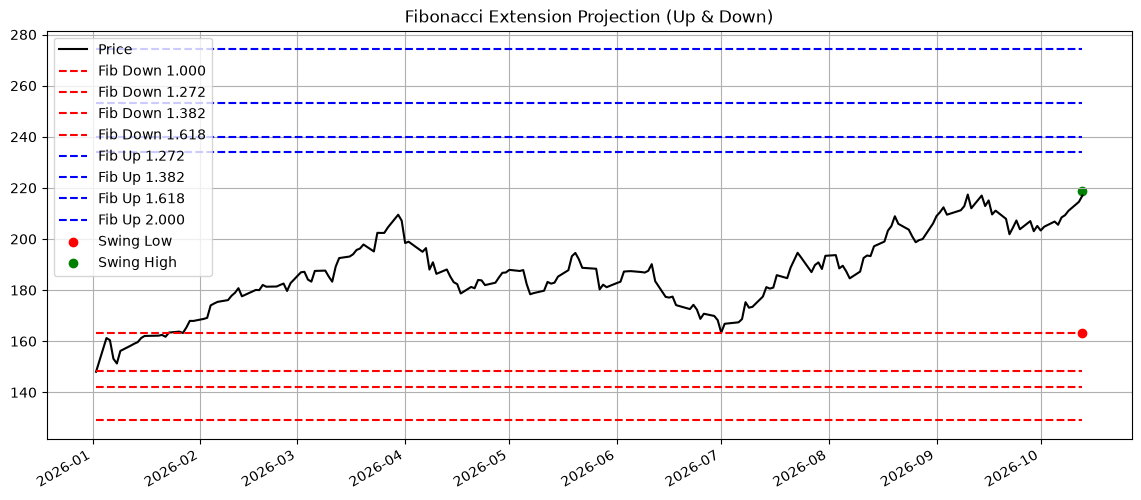

In [14]:
fib_result = fibonacci_extension.compute_fibonacci_extension(df.copy().reset_index())
fib_result

In [15]:
output_dir = Path("/workspace/data/figures/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{cvx}_fibonacci_extension_{dt.datetime.now().strftime('%Y-%m-%d')}.png"
fib_result["plot_obj"].savefig(output_path, dpi=300, bbox_inches="tight")

#### 財務データ

In [16]:
response = request_api.update_corp_finance_data(
    code=cvx,
    market=None
)
response

{'result': True}

In [17]:
cvx_financials_data = request_api.get_corp_financials_data(code=cvx, market=None)
cvx_balance_sheet_data = request_api.get_corp_balance_sheet_data(code=cvx, market=None)
cvx_cash_flow_data = request_api.get_corp_cash_flow_data(code=cvx, market=None)
cvx_earnings_data = request_api.get_corp_earnings_data(code=cvx, market=None)
cvx_quarterly_earnings_data = request_api.get_corp_quarterly_earnings_data(code=cvx, market=None)

In [18]:
# ４年分の財務データ
cvx_financials_data_df = pd.DataFrame(cvx_financials_data['results'])
# ４年分のバランスシート
cvx_balance_sheet_data_df = pd.DataFrame(cvx_balance_sheet_data['results'])
# ４年分のキャッシュフロー
cvx_cash_flow_data_df = pd.DataFrame(cvx_cash_flow_data['results'])
# ４年分の収益データ
cvx_earnings_data_df = pd.DataFrame(cvx_earnings_data['results'])
# ４年分の四半期収益データ
cvx_quarterly_earnings_data_df = pd.DataFrame(cvx_quarterly_earnings_data['results'])

In [19]:
"""
◆ 1. 株価・市場データ
• 現在株価（Price）
• 時価総額（Market Cap）
• 出来高（Volume）
• 52週高値・安値
• Beta（ボラティリティ指標）ß
"""
stock_prices_market_data.stock_prices_and_market_data(
    code=cvx,
    market=None,
    bs_df=cvx_balance_sheet_data_df
)

取得件数: 461
取得件数: 461
取得件数: 460
取得件数: 460
取得件数: 458
取得件数: 458
取得件数: 459
取得件数: 459
取得件数: 458
取得件数: 458


,close,market_cap,shares_outstanding,higher_rate_par_52_weeks,lower_rate_par_52_weeks,beta
0,70.732128,NaN,NaN,98.791792,38.860498,1.286206
1,87.006076,2.125277e+11,2.442677e+09,161.427935,75.992862,0.607081
2,136.158643,3.325915e+11,2.442677e+09,161.427935,111.783052,0.664809
3,139.248383,3.401388e+11,2.442677e+09,153.108695,124.448164,0.552744
4,136.808106,3.341780e+11,2.442677e+09,158.830340,124.123757,0.607312


In [20]:
"""
◆ 2. 財務データ（Financials）+ EPS（Earnings Per Share）+ PBR（Price-to-Book Ratio）
• 売上高（Revenue）
• 営業利益（Operating Income）
• 純利益（Net Income）
• EBITDA（企業による）
• 総資産（Total Assets）
• 総負債（Total Liabilities）
• 現金（Cash）
• 希釈EPS（Diluted EPS）
• 基本EPS（Basic EPS）
• 営業キャッシュフロー（Operating Cash Flow）
• フリーキャッシュフロー（Free Cash Flow）
"""
financial_df = financial.calc_financial(
    code = cvx,
    market = None,
)
financial_df.to_markdown()

取得件数: 6944


'|    | date                |       revenue |     earnings |   total_assets |   total_debt |   cash_and_cash_equivalents |       EBITDA |   operating_income |   basic_eps |   diluted_eps |   operating_cash_flow |   free_cash_flow |\n|---:|:--------------------|--------------:|-------------:|---------------:|-------------:|----------------------------:|-------------:|-------------------:|------------:|--------------:|----------------------:|-----------------:|\n|  0 | 2021-12-31 00:00:00 | nan           | nan          |  nan           | nan          |                nan          | nan          |       nan          |      nan    |        nan    |          nan          |     nan          |\n|  1 | 2022-12-31 00:00:00 |   2.35717e+11 |   3.5465e+10 |    2.57709e+11 |   2.3339e+10 |                  1.7678e+10 |   6.5485e+10 |         3.995e+10  |       18.36 |         18.28 |            4.9602e+10 |       3.7628e+10 |\n|  2 | 2023-12-31 00:00:00 |   1.96913e+11 |   2.1369e+10 |    2.61632e